# Trend analysis: climate drivers of fire in Brazil
**NASA Space Apps 2026 · Be An Earth System Trend Detective**

Reads the monthly files produced by the ingestion notebook (`MyDrive/fogo_trends/data/`) and answers, for each variable: **what is changing, where, by how much, and whether it is significant.**

Method (summary):
1. Aggregation by **fire season** (default Aug–Oct) → one value per year, 2001–2025. This removes seasonality.
2. **Sen slope** (robust to outliers) and the **Mann-Kendall** test, with three versions of the p-value: classic, Hamed-Rao, and a **test against an AR(1) null** (the primary one, see the sanity-check cell).
3. **FDR** (Benjamini-Hochberg, α_FDR = 2·α, Wilks 2016) for the spatial field: stippling marks only pixels that survive the multiple-testing correction.
4. **By biome**: area-weighted mean series, trend, and change point (Pettitt).

⚠️ Trend ≠ cause. Correlation with fire indicates consistency, not causation.

## 1. Setup

In [1]:
!pip -q install pymannkendall regionmask geobr statsmodels
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
import pymannkendall as mk

ROOT = Path('/content/drive/MyDrive/fogo_trends'); DATA = ROOT/'data'; OUT = ROOT/'resultados'; OUT.mkdir(exist_ok=True)

# ---- parameters ----
SEASON = [8, 9, 10]                 # fire-season months (Aug–Oct). Also try [5,6,7,8,9] (dry season)
SEASON_NAME = 'Aug–Oct'
YEARS = list(range(2001, 2026))     # complete years only
ALPHA = 0.05                        # global level; FDR uses 2*ALPHA (Wilks, 2016)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})

## 2. Statistical functions
Validated against `pymannkendall` (identical slope and p-values) and tested on synthetic noise.

In [3]:
import numpy as np
from scipy import stats

def mk_sen_hr(X, alpha_acf=0.05):
    """Vectorized trend for m series of n years. X: (n, m).
    Returns dict (m,): slope (units/year), S, p_naive (classic Mann-Kendall), p_hr (Hamed-Rao), nns (n/n*).
    No tie correction: use on continuous fields (rain, moisture, VPD). For series with many
    ties (counts), use pymannkendall directly."""
    n, m = X.shape
    t = np.arange(n, dtype=float)
    i, j = np.triu_indices(n, 1)
    dx = X[j] - X[i]
    S = np.sign(dx).sum(0)
    slope = np.median(dx / (j - i)[:, None], axis=0)           # Sen slope
    var0 = n * (n - 1) * (2 * n + 5) / 18.0
    def pval(S, var):
        z = np.where(S > 0, (S - 1), np.where(S < 0, (S + 1), 0.0)) / np.sqrt(var)
        return 2 * (1 - stats.norm.cdf(np.abs(z)))
    p_naive = pval(S, var0)
    # Hamed-Rao: autocorrelation of the ranks of the detrended series, significant lags only
    y = X - slope[None, :] * t[:, None]
    r = stats.rankdata(y, axis=0)
    r = r - r.mean(0)
    den = (r ** 2).sum(0)
    ci = stats.norm.ppf(1 - alpha_acf / 2) / np.sqrt(n)
    corr = np.zeros(m)
    for k in range(1, n - 2):
        rho = (r[:-k] * r[k:]).sum(0) / den
        corr += np.where(np.abs(rho) > ci, (n - k) * (n - k - 1) * (n - k - 2) * rho, 0.0)
    nns = 1 + 2.0 / (n * (n - 1) * (n - 2)) * corr
    # conservative: the correction can only INCREASE the variance (n/n* >= 1). Avoids negative/NaN variance
    # when the weighted autocorrelation comes out negative (the reference library returns NaN in those cases).
    p_hr = pval(S, var0 * np.maximum(nns, 1.0))
    return dict(slope=slope, S=S, p_naive=p_naive, p_hr=p_hr, nns=nns)

def fdr_mask(p, alpha_global=0.05):
    """False discovery rate control (Benjamini-Hochberg) with alpha_FDR = 2*alpha_global (Wilks, 2016)."""
    from statsmodels.stats.multitest import multipletests
    ok = np.isfinite(p)
    out = np.zeros(p.shape, bool)
    if ok.sum():
        out[ok] = multipletests(p[ok], alpha=2 * alpha_global, method='fdr_bh')[0]
    return out

def pettitt(x):
    """Pettitt test: single change point. Returns (index of the last obs. before the shift, p)."""
    x = np.asarray(x, float); n = len(x)
    r = stats.rankdata(x)
    tt = np.arange(1, n)
    U = 2 * np.cumsum(r)[:-1] - tt * (n + 1)
    K = np.abs(U).max()
    return int(np.abs(U).argmax()), float(min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2))))


def p_ar1_surrogate(X, slope, S, nsim=4000, seed=0, nbins=30):
    """Mann-Kendall p-value against an AR(1) null with φ estimated for each series (corrected for the
    small-sample bias, Kendall 1954: E[φ̂] ≈ φ − (1+3φ)/n). Compares the observed |S| with the distribution of |S|
    simulated on trend-free AR(1) noise. More robust than Hamed-Rao for short series (~25 points)."""
    n, m = X.shape
    rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=float)
    y = X - slope[None, :] * t[:, None]
    y = y - y.mean(0)
    den = (y ** 2).sum(0)
    phi_hat = np.where(den > 0, (y[:-1] * y[1:]).sum(0) / np.where(den > 0, den, 1), 0.0)
    phi = np.clip((n * phi_hat + 1) / (n - 3), -0.5, 0.95)
    centers = np.linspace(-0.5, 0.95, nbins)
    b = np.abs(phi[:, None] - centers[None, :]).argmin(1)
    i, j = np.triu_indices(n, 1)
    p = np.full(m, np.nan)
    for k in np.unique(b):
        ph = centers[k]
        e = rng.normal(size=(n + 50, nsim)); x = np.zeros_like(e)
        for tt in range(1, n + 50): x[tt] = ph * x[tt - 1] + e[tt]
        x = x[50:]
        Ssim = np.abs(np.sign(x[j] - x[i]).sum(0))
        Ssim.sort()
        sel = b == k
        cnt = nsim - np.searchsorted(Ssim, np.abs(S[sel]), side='left')   # number of sims with |S| >= |S_obs|
        p[sel] = (cnt + 1) / (nsim + 1)
    return p


## 2b. Figure style (publication quality)
All figures are saved to `resultados/figures/` as **300 dpi PNG + vector PDF**. Validated categorical palette (colorblind-safe), blue↔red diverging scale with a neutral midpoint (red = change in the direction that favors fire). `LANG='pt'` renders everything in Portuguese; `TITLES=False` removes titles (for a paper, use the caption).

In [4]:
# ============================================================
# FIGURE STYLE (publication quality): validated palette, thin marks, selective labels
# ============================================================
LANG   = 'en'     # 'en' | 'pt'  (language of ALL figure text)
TITLES = True     # True: headline title + subtitle (video/slides). False: figure only (paper; use the caption)

import numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb, to_hex, Normalize
from matplotlib import patheffects as pe
from scipy.ndimage import gaussian_filter

INK = dict(primary='#0b0b0b', secondary='#52514e', muted='#898781', grid='#e1e0d9', base='#c3c2b7',
           surface='#ffffff', neutral='#f0efec')
# Categorical (validated palette, fixed order). Color follows the ENTITY: each biome always keeps its color.
BIOME_COLOR = {'Amazon': '#2a78d6', 'Cerrado': '#eb6834', 'Pantanal': '#1baf7a'}
CONTEXT_GRAY = '#d9d8d2'            # context biomes (emphasis: highlight 3, fade the rest)
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']     # slots 1-4 (validated: adjacent pairs ΔE>=9)
SEQ_BLUE = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5',
            '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']   # sequential 100->700

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Inter', 'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 8.5, 'text.color': INK['primary'],
    'axes.titlesize': 9, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 8, 'axes.labelcolor': INK['secondary'], 'axes.edgecolor': INK['base'],
    'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.facecolor': INK['surface'], 'figure.facecolor': INK['surface'], 'savefig.facecolor': INK['surface'],
    'axes.grid': False, 'grid.color': INK['grid'], 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'xtick.color': INK['muted'], 'ytick.color': INK['muted'], 'xtick.labelcolor': INK['secondary'],
    'ytick.labelcolor': INK['secondary'], 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'xtick.major.size': 3, 'ytick.major.size': 3, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'legend.frameon': False, 'legend.fontsize': 7.5, 'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round',
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.12,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

# ---------- diverging ramp: blue <-> red, neutral gray midpoint, arms with the SAME lightness ----------
def _lin(c): c = np.asarray(c, float); return np.where(c <= 0.04045, c/12.92, ((c+0.055)/1.055)**2.4)
def _gam(c): c = np.clip(c, 0, 1); return np.where(c <= 0.0031308, 12.92*c, 1.055*c**(1/2.4)-0.055)
def hex2oklch(h):
    r, g, b = _lin(to_rgb(h))
    l = 0.4122214708*r+0.5363325363*g+0.0514459929*b; m = 0.2119034982*r+0.6806995451*g+0.1073969566*b
    s = 0.0883024619*r+0.2817188376*g+0.6299787005*b
    l_, m_, s_ = np.cbrt([l, m, s])
    L = 0.2104542553*l_+0.7936177850*m_-0.0040720468*s_
    a = 1.9779984951*l_-2.4285922050*m_+0.4505937099*s_
    bb = 0.0259040371*l_+0.7827717662*m_-0.8086757660*s_
    return L, float(np.hypot(a, bb)), float(np.degrees(np.arctan2(bb, a)) % 360)
def oklch2lin(L, C, h):
    a, b = C*np.cos(np.radians(h)), C*np.sin(np.radians(h))
    l_, m_, s_ = L+0.3963377774*a+0.2158037573*b, L-0.1055613458*a-0.0638541728*b, L-0.0894841775*a-1.2914855480*b
    l, m, s = l_**3, m_**3, s_**3
    return np.array([4.0767416621*l-3.3077115913*m+0.2309699292*s, -1.2684380046*l+2.6097574011*m-0.3413193965*s,
                     -0.0041960863*l-0.7034186147*m+1.7076147010*s])
def _in_gamut(rgb): return bool((rgb >= -1e-4).all() and (rgb <= 1+1e-4).all())
def _red_step(L, C, h):
    while C > 0 and not _in_gamut(oklch2lin(L, C, h)): C -= 0.002
    return to_hex(_gam(oklch2lin(L, max(C, 0), h)))

_h_red = hex2oklch('#e34948')[2]
BLUE_ARM = SEQ_BLUE[:]                                           # light -> dark
RED_ARM = [_red_step(hex2oklch(c)[0], hex2oklch(c)[1], _h_red) for c in BLUE_ARM]   # same L at each step
# HEAT: negative = blue, positive = red.  WATER: the reverse (negative = red).
CMAP_HEAT = LinearSegmentedColormap.from_list('heat', BLUE_ARM[::-1] + [INK['neutral']] + RED_ARM, N=512)
CMAP_WATER = CMAP_HEAT.reversed()
CMAP_SEQ = LinearSegmentedColormap.from_list('seq', SEQ_BLUE, N=256)
FIRE_RED, FIRE_BLUE = RED_ARM[7], BLUE_ARM[7]                   # polarity of the anomaly bars
# sign that FAVORS fire in each variable (+1: an increase favors; -1: a decrease favors)
FIRE_SIGN = {'precip': -1, 'sm_sup': -1, 'sm_raiz': -1, 'vpd': +1, 't2m': +1, 'tair': +1, 'cpc': +1}
def cmap_for(k): return CMAP_HEAT if FIRE_SIGN.get(k, 1) > 0 else CMAP_WATER

# ---------- text (en/pt) ----------
T = {
 'pt': dict(sig='Pontilhado: tendência significativa (p < 0,05, nulo AR(1), com correção FDR)',
            favors='Vermelho = muda no sentido que favorece o fogo', per_dec='por década',
            pct_dec='% por década', less_rain='menos chuva', more_rain='mais chuva', less_sm='mais seco', more_sm='mais úmido',
            cooler='mais frio', warmer='mais quente', lowvpd='menor VPD', highvpd='maior VPD',
            year='Ano', fp='Falsos positivos (% dos pixels)', fp_t='Falsos positivos em ruído sem tendência alguma',
            fp_sub='Fração de séries de 25 anos declaradas "com tendência" (p < 0,05); o esperado seria 5%',
            autocorr='Autocorrelação da série (φ)', nominal='nível nominal 5%', ns='n.s.', mean_ref='Média 2001–{y}',
            study='Área de estudo: os biomas brasileiros', other='Outros biomas', anomaly='Anomalia', break_='mudança',
            m_classic='Mann-Kendall clássico', m_hr='Hamed-Rao', m_ar1='Teste AR(1)', m_fdr='Teste AR(1) + FDR',
            maps_t='Onde o clima do fogo está mudando', maps_sub='Tendência na estação de fogo ({s}), {a}–{b}, grade de 0,25°',
            series_t='A mesma tendência, bioma a bioma', series_sub='Anomalia anual da estação de fogo ({s}); linha = inclinação de Sen',
            rob_a='Concordância entre produtos', rob_b='Sensibilidade à janela temporal', window='Janela',
            density='pixels', corr_t='Fogo e clima caminham juntos?', fire_t='Focos de calor na estação de fogo',
            rho='Correlação de Spearman (ρ)', sens_t='A tendência resiste a mudar a janela?',
            sens_sub='Tendência por década por bioma; ponto cheio = p < 0,05', fire_total='Focos de calor por mês (satélite de referência)',
            fire_season='Focos na estação de fogo ({s}) por bioma', gaps='meses sem arquivo aparecem como lacunas',
            src='Fontes: NASA GLDAS, GPM IMERG, MERRA-2, FIRMS; NOAA CPC; IBGE', samegrid='MERRA-2 (°C por década)', gldasgrid='GLDAS (°C por década)'),
 'en': dict(sig='Stippling: significant trend (p < 0.05, AR(1) null, FDR-corrected)',
            favors='Red = change that favors fire', per_dec='per decade',
            pct_dec='% per decade', less_rain='less rain', more_rain='more rain', less_sm='drier', more_sm='wetter',
            cooler='cooler', warmer='warmer', lowvpd='lower VPD', highvpd='higher VPD',
            year='Year', fp='False positives (% of pixels)', fp_t='False positives in trend-free noise',
            fp_sub='Share of 25-year series declared "trending" (p < 0.05); the expected rate is 5%',
            autocorr='Series autocorrelation (φ)', nominal='nominal 5% level', ns='n.s.', mean_ref='Mean 2001–{y}',
            study='Study area: Brazilian biomes', other='Other biomes', anomaly='Anomaly', break_='shift',
            m_classic='Classic Mann-Kendall', m_hr='Hamed-Rao', m_ar1='AR(1) test', m_fdr='AR(1) test + FDR',
            maps_t='Where fire-season climate is changing', maps_sub='Fire-season trend ({s}), {a}–{b}, 0.25° grid',
            series_t='The same trends, biome by biome', series_sub='Annual fire-season anomaly ({s}); line = Sen slope',
            rob_a='Agreement between products', rob_b='Sensitivity to the time window', window='Window',
            density='pixels', corr_t='Do fire and climate move together?', fire_t='Active fires in the fire season',
            rho='Spearman correlation (ρ)', sens_t='Does the trend survive changing the window?',
            sens_sub='Trend per decade by biome; filled dot = p < 0.05', fire_total='Active fires per month (reference satellite)',
            fire_season='Fire-season ({s}) active fires by biome', gaps='months without a file show as gaps',
            src='Sources: NASA GLDAS, GPM IMERG, MERRA-2, FIRMS; NOAA CPC; IBGE', samegrid='MERRA-2 (°C per decade)', gldasgrid='GLDAS (°C per decade)'),
}
def tr(k, **kw): return T[LANG][k].format(**kw) if kw else T[LANG][k]
_BIO_PT = {'Amazon': 'Amazônia', 'Atlantic Forest': 'Mata Atlântica'}      # only used when LANG='pt'
def bname(b): return b if LANG == 'en' else _BIO_PT.get(b, b)
_VAR = {'precip': ('Precipitação', 'Precipitation'), 'sm_sup': ('Umidade do solo 0–10 cm', 'Soil moisture 0–10 cm'),
        'sm_raiz': ('Umidade do solo 10–40 cm', 'Soil moisture 10–40 cm'), 'vpd': ('Déficit de pressão de vapor', 'Vapor pressure deficit'),
        't2m': ('Temperatura do ar (MERRA-2)', 'Air temperature (MERRA-2)'), 'tair': ('Temperatura do ar (GLDAS)', 'Air temperature (GLDAS)'), 'cpc': ('Temperatura do ar (CPC, estações)', 'Air temperature (CPC, stations)')}
def vname(k): return _VAR[k][1 if LANG == 'en' else 0]
_UNIT = {'precip': '%', 'sm_sup': '%', 'sm_raiz': '%', 'vpd': 'kPa', 't2m': '°C', 'tair': '°C', 'cpc': '°C'}
def num(x, nd=1):
    s = f'{x:+.{nd}f}'.replace('-', '−')
    return s.replace('.', ',') if LANG == 'pt' else s
def pfmt(p): return tr('ns') if p >= .1 else ('p < 0,01' if LANG == 'pt' else 'p < 0.01') if p < .01 else (f'p = {p:.2f}'.replace('.', ',') if LANG == 'pt' else f'p = {p:.2f}')

# ---------- utilities ----------
FIGDIR = None
def _figdir():
    global FIGDIR
    if FIGDIR is None:
        FIGDIR = (OUT / 'figures'); FIGDIR.mkdir(exist_ok=True)
    return FIGDIR
def save_fig(fig, name):
    d = _figdir()
    fig.savefig(d / f'{name}.png'); fig.savefig(d / f'{name}.pdf')     # PNG 300 dpi + vector PDF (embedded fonts)
    plt.show(); print('saved:', d / f'{name}.png', '(+ .pdf)')
def headline(fig, title, sub=None, x=0.012, y=0.995):
    if not TITLES: return
    fig.text(x, y, title, fontsize=12.5, fontweight='bold', va='top', ha='left', color=INK['primary'])
    if sub: fig.text(x, y - 0.27 / fig.get_figheight(), sub, fontsize=8.5, va='top', ha='left', color=INK['secondary'])
def footnote(fig, text, y=0.004):
    fig.text(0.012, y, text, fontsize=7, va='bottom', ha='left', color=INK['muted'])
def panel_label(ax, letter, dx=-0.02, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=10, fontweight='bold', va='bottom', ha='right', color=INK['primary'])
def halo(): return [pe.withStroke(linewidth=2.2, foreground='white')]
def clean_axes(ax, grid='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    if grid: ax.grid(axis=grid, color=INK['grid'], lw=0.6); ax.set_axisbelow(True)
def nice_lim(x):
    x = float(x) if np.isfinite(x) and x > 0 else 1.0
    e = 10 ** np.floor(np.log10(x)); m = x / e
    return next(s for s in (1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10) if m <= s + 1e-9) * e

# ============================================================
# FIGURES (use the notebook variables: TM, BIO, SER, YEARS, LON, LAT, ...)
# ============================================================
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba

def _sgn(v, _=None): return '0' if abs(v) < 1e-9 else f"{v:+g}".replace('-', '−')
def _lonlat(ax):
    ew, ns = ('W', 'S') if LANG == 'en' else ('O', 'S')
    ax.set_xticks([-70, -60, -50, -40]); ax.set_xticklabels([f'{abs(v)}°{ew}' for v in (-70, -60, -50, -40)])
    ax.set_yticks([-30, -20, -10, 0]); ax.set_yticklabels([f'{abs(v)}°{ns}' if v else '0°' for v in (-30, -20, -10, 0)])
def _map_axes(ax):
    ax.set_aspect('equal'); ax.set_xlim(-74.2, -34); ax.set_ylim(-34.2, 5.8); _lonlat(ax)
    ax.grid(True, color=INK['grid'], lw=0.4); ax.set_axisbelow(True)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(length=0, labelsize=6.5, labelcolor=INK['muted'])
def _outlines(ax, borders=True):
    m = gaussian_filter((BIO >= 0).astype(float), 0.8)
    ax.contour(LON, LAT, m, levels=[0.5], colors=INK['primary'], linewidths=0.7)
    if borders:
        for b in range(len(BIO_NAMES)):
            mb = gaussian_filter((BIO == b).astype(float), 0.8)
            if mb.max() > 0.5: ax.contour(LON, LAT, mb, levels=[0.5], colors=INK['secondary'], linewidths=0.3, alpha=0.7)
def _ends(k):
    return {'precip': ('less_rain', 'more_rain'), 'sm_sup': ('less_sm', 'more_sm'), 'sm_raiz': ('less_sm', 'more_sm'),
            'vpd': ('lowvpd', 'highvpd'), 't2m': ('cooler', 'warmer'), 'tair': ('cooler', 'warmer'), 'cpc': ('cooler', 'warmer')}[k]

def draw_trend_map(ax, k):
    t = TM[k]; z = t['slope_dec'].values; inside = BIO >= 0
    vals = z[inside & np.isfinite(z)]
    lim = nice_lim(np.percentile(np.abs(vals), 98)); norm = Normalize(-lim, lim); cm = cmap_for(k)
    kw = dict(cmap=cm, norm=norm, shading='nearest', rasterized=True, linewidth=0)
    ax.pcolormesh(LON, LAT, np.ma.masked_invalid(z), alpha=0.2, **kw)                     # context outside Brazil, faded
    ax.pcolormesh(LON, LAT, np.ma.masked_invalid(np.where(inside, z, np.nan)), **kw)
    yy, xx = np.where(t['sig_fdr'].values.astype(bool) & inside)
    keep = (yy % 2 == 0) & (xx % 2 == 0)                                                    # sparse stippling = legible
    ax.scatter(LON[xx[keep]], LAT[yy[keep]], s=1.0, c=INK['primary'], alpha=0.5, lw=0, rasterized=True)
    _outlines(ax); _map_axes(ax)
    return mpl.cm.ScalarMappable(norm=norm, cmap=cm), lim

def _cbar(fig, ax, sm, k):
    cb = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.045, pad=0.03, aspect=32, shrink=0.72, extend='both')
    cb.outline.set_visible(False); cb.ax.tick_params(length=2, labelsize=6.5, labelcolor=INK['secondary'])
    cb.ax.xaxis.set_major_locator(MaxNLocator(5)); cb.ax.xaxis.set_major_formatter(FuncFormatter(_sgn))
    unit = tr('pct_dec') if _UNIT[k] == '%' else f"{_UNIT[k]} {tr('per_dec')}"
    cb.set_label(unit, fontsize=7, color=INK['secondary'], labelpad=2)
    l, r = _ends(k)
    cb.ax.text(0, 1.9, '← ' + tr(l), transform=cb.ax.transAxes, fontsize=6.5, color=INK['secondary'], ha='left', va='bottom')
    cb.ax.text(1, 1.9, tr(r) + ' →', transform=cb.ax.transAxes, fontsize=6.5, color=INK['secondary'], ha='right', va='bottom')

def fig_mapas(keys=('precip', 'sm_raiz', 'vpd', 't2m'), name='fig2_trend_maps', ncols=2):
    keys = [k for k in keys if k in TM]; nrows = int(np.ceil(len(keys) / ncols))
    fig = plt.figure(figsize=(3.55 * ncols + 0.2, 3.65 * nrows + (0.9 if TITLES else 0.35)), layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.035, 1, (1 - 0.8 / fig.get_figheight()) if TITLES else 0.985), w_pad=0.04, h_pad=0.06)
    axs = np.atleast_1d(fig.subplots(nrows, ncols)).ravel()
    for i, (ax, k) in enumerate(zip(axs, keys)):
        sm, lim = draw_trend_map(ax, k); _cbar(fig, ax, sm, k)
        ax.set_title(f"{'abcdef'[i]}   {vname(k)}", fontsize=8.5, pad=5)
    for ax in axs[len(keys):]: ax.axis('off')
    s = f"{SEASON_NAME}"; headline(fig, tr('maps_t'), tr('maps_sub', s=s, a=YEARS[0], b=YEARS[-1]))
    footnote(fig, tr('sig') + '.  ' + tr('favors') + '.   ' + tr('src'))
    save_fig(fig, name)

def fig_area_estudo(name='fig1_study_area'):
    fig, ax = plt.subplots(figsize=(5.2, 5.6), layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.03, 1, 0.9 if TITLES else 0.985))
    for b, nm in enumerate(BIO_NAMES):
        mk_ = gaussian_filter((BIO == b).astype(float), 0.8)
        if mk_.max() <= 0.5: continue
        col = BIOME_COLOR.get(nm, CONTEXT_GRAY)
        ax.contourf(LON, LAT, mk_, levels=[0.5, 1.5], colors=[col], alpha=0.92 if nm in BIOME_COLOR else 1)
        ax.contour(LON, LAT, mk_, levels=[0.5], colors='white', linewidths=0.9)             # surface-colored gap between biomes
    for b, nm in enumerate(BIO_NAMES):
        yy, xx = np.where(BIO == b)
        if len(yy) == 0: continue
        cy, cx = LAT[yy].mean(), LON[xx].mean(); i = np.argmin((LAT[yy] - cy) ** 2 + (LON[xx] - cx) ** 2)   # medoid: label inside the biome
        ax.text(LON[xx[i]], LAT[yy[i]], bname(nm), ha='center', va='center', fontsize=7.5 if nm in ('Amazon', 'Cerrado') else 6.3,
                fontweight='bold' if nm in BIOME_COLOR else 'normal', color=INK['primary'] if nm not in BIOME_COLOR else 'white',
                path_effects=[pe.withStroke(linewidth=1.6, foreground=BIOME_COLOR.get(nm, CONTEXT_GRAY))])
    _map_axes(ax)
    h = [Patch(fc=BIOME_COLOR[n], ec='none', label=bname(n)) for n in BIOME_COLOR if n in BIO_NAMES] + [Patch(fc=CONTEXT_GRAY, ec='none', label=tr('other'))]
    ax.legend(handles=h, loc='lower left', fontsize=7, handlelength=1.1, borderaxespad=0.2)
    headline(fig, tr('study')); footnote(fig, tr('src'))
    save_fig(fig, name)

def fig_sanidade(df, name='fig3_false_positives'):
    cols = ['Classic MK', 'Hamed-Rao', 'AR(1) surrogate', 'surrogate + FDR']; lab = [tr('m_classic'), tr('m_hr'), tr('m_ar1'), tr('m_fdr')]
    fig, ax = plt.subplots(figsize=(6.2, 3.7), layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.03, 1, 0.86 if TITLES else 0.985))
    x = np.array(df.index, float); clean_axes(ax, 'y')
    ax.axhline(5, color=INK['secondary'], lw=0.9); ax.text(x[-1] + 0.025, 5, tr('nominal'), fontsize=7, color=INK['secondary'], ha='left', va='center')
    ends = []
    for c, l, col in zip(cols, lab, SERIES):
        y = df[c].values * 100
        ax.plot(x, y, color=col, lw=2, zorder=3); ax.plot(x, y, 'o', ms=5.5, mfc=col, mec='white', mew=0.9, zorder=4)
        ends.append((y[-1], l))
    for y, l in ends:                                                                          # direct labels at line ends
        ax.text(x[-1] + 0.025, y, f'{l}  {y:.0f}%' if y >= 10 else f'{l}  {y:.1f}%'.replace('.', ',' if LANG == 'pt' else '.'), fontsize=7.5, va='center', color=INK['primary'])
    ax.set_xlim(x[0] - 0.03, x[-1] + 0.55); ax.set_ylim(0, max(52, max(e[0] for e in ends) * 1.1))
    ax.set_xticks(x); ax.set_xticklabels([f'{v:g}'.replace('.', ',' if LANG == 'pt' else '.') for v in x])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'))
    ax.set_xlabel(tr('autocorr')); ax.set_ylabel(tr('fp'))
    ax.legend(handles=[Line2D([0], [0], color=c, lw=2, marker='o', ms=5, mec='white') for c in SERIES], labels=lab, loc='upper left', fontsize=7, ncol=1)
    headline(fig, tr('fp_t'), tr('fp_sub')); footnote(fig, 'n = 25 years; 10,000 simulated series per φ level' if LANG == 'en' else 'n = 25 anos; 10 000 séries simuladas por nível de φ')
    save_fig(fig, name)

def _pet(s):
    r = mk_sen_hr(s[:, None]); sl = r['slope'][0]; t = np.arange(len(s)); ic = np.median(s - sl * t)
    pa = p_ar1_surrogate(s[:, None], r['slope'], r['S'], nsim=10000)[0]; ib, pp = pettitt(s)
    return sl, ic, pa, ib, pp

def fig_series_biomas(focus=('t2m', 'vpd', 'sm_raiz', 'precip'), biomes=('Amazon', 'Cerrado', 'Pantanal'), name='fig4_biome_series'):
    focus = [k for k in focus if k in ANN]; biomes = [b for b in biomes if any((k, b) in SER for k in focus)]
    nr, nc = len(focus), len(biomes); yrs = np.array(YEARS)
    fig, axs = plt.subplots(nr, nc, figsize=(7.2, 1.45 * nr + (1.15 if TITLES else 0.55)), sharex=True, sharey='row', squeeze=False, layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.03, 1, 0.9 if TITLES else 0.985), h_pad=0.05, w_pad=0.03)
    for i, k in enumerate(focus):
        pct = VARS[k]['pct']
        for j, b in enumerate(biomes):
            ax = axs[i, j]; s = SER.get((k, b))
            if s is None: ax.axis('off'); continue
            base = s.mean(); an = (s - base) / base * 100 if pct else s - base
            sl, ic, pa, ib, pp = _pet(s)
            cols = [FIRE_RED if np.sign(a) == FIRE_SIGN[k] else FIRE_BLUE for a in an]
            ax.bar(yrs, an, width=0.74, color=cols, lw=0, zorder=2); ax.axhline(0, color=INK['base'], lw=0.8, zorder=1)
            tt = np.arange(len(s)); ln = ic + sl * tt; ln = (ln - base) / base * 100 if pct else ln - base
            ax.plot(yrs, ln, color=INK['primary'], lw=1.5, zorder=4)
            clean_axes(ax, 'y')
            dec = sl * 10 * (100 / base if pct else 1)
            right = sl < 0; xx_, ha_ = (0.97, 'right') if right else (0.03, 'left')
            ax.text(xx_, 0.96, f"{num(dec)} {'%' if pct else _UNIT[k]}/{'déc' if LANG == 'pt' else 'dec'}", transform=ax.transAxes, va='top', ha=ha_, fontsize=7.5,
                    fontweight='bold', path_effects=halo(), zorder=8)
            ax.text(xx_, 0.80, pfmt(pa) + (f" · {tr('break_')} {yrs[ib] + 1}" if pp < 0.1 else ''), transform=ax.transAxes, va='top', ha=ha_, fontsize=6.6,
                    color=INK['secondary'], path_effects=halo(), zorder=8)
            if pp < 0.1:
                xb = yrs[ib] + 0.5; ax.plot([xb], [1], marker='v', ms=4, color=INK['muted'], transform=ax.get_xaxis_transform(), clip_on=False, zorder=6)
                ax.axvline(xb, color=INK['muted'], lw=0.7, ymax=0.97, zorder=3, ls=(0, (1, 2)))
            if i == 0: ax.set_title('     ' + bname(b), fontsize=9, pad=8, color=INK['primary'], loc='left')
            if j == 0:
                ax.set_ylabel(f"{vname(k)}\n({'%' if pct else _UNIT[k]})", fontsize=7.2, linespacing=1.15)
            ax.tick_params(labelsize=6.8)
    for i in range(nr):                                                                           # headroom for the text, common scale per row
        ys = [np.r_[[p.get_height() for p in ax.patches], ax.lines[0].get_ydata()] for ax in axs[i] if ax.axison and ax.patches]
        lo, hi = min(np.min(y) for y in ys), max(np.max(y) for y in ys); r = (hi - lo) or 1
        axs[i, 0].set_ylim(min(lo, 0) - 0.08 * r, max(hi, 0) + 0.55 * r)
    for ax in axs[-1]: ax.set_xticks([2001, 2006, 2011, 2016, 2021]); ax.set_xlim(YEARS[0] - 0.9, YEARS[-1] + 0.9)
    for j, b in enumerate(biomes):                                                              # biome identity: color dot
        axs[0, j].plot([0.025], [1.115], 'o', ms=6, color=BIOME_COLOR.get(b, CONTEXT_GRAY), transform=axs[0, j].transAxes, clip_on=False)
    headline(fig, tr('series_t'), tr('series_sub', s=SEASON_NAME))
    footnote(fig, tr('favors') + '.  ' + ('Barras: anomalia em relação à média do período; linha: inclinação de Sen; ▼ pontilhado: mudança de Pettitt (p < 0,1).' if LANG == 'pt'
              else 'Bars: anomaly vs. period mean; line: Sen slope; ▼ dotted: Pettitt shift (p < 0.1).'))
    save_fig(fig, name)

def _detr(x):
    x = np.asarray(x, float); sl = mk_sen_hr(x[:, None])['slope'][0]; return x - sl * np.arange(len(x))

def fig_fogo(fb, name='fig5_fire_and_climate'):
    from scipy.stats import spearmanr
    bio = [b for b in ['Amazon', 'Cerrado', 'Pantanal'] if b in fb and fb[b].notna().all()]
    drv = [k for k in ['t2m', 'vpd', 'sm_raiz', 'precip'] if k in ANN]
    fig = plt.figure(figsize=(7.2, 6.3 if TITLES else 5.6), layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.03, 1, (1 - 0.85 / fig.get_figheight()) if TITLES else 0.985), h_pad=0.08)
    gs = fig.add_gridspec(2, len(bio), height_ratios=[1, 0.95])
    yrs = np.array(fb.index); _ix = [YEARS.index(y) for y in fb.index]
    for j, b in enumerate(bio):
        ax = fig.add_subplot(gs[0, j]); s = fb[b].values.astype(float); col = BIOME_COLOR.get(b, CONTEXT_GRAY)
        sl, ic, pa, ib, pp = _pet(s)
        ax.plot(yrs, s, color=col, lw=2, zorder=3); ax.plot(yrs, s, 'o', ms=4, mfc=col, mec='white', mew=0.7, zorder=4)
        ax.plot(yrs, ic + sl * np.arange(len(s)), color=INK['primary'], lw=1.3, zorder=5)
        clean_axes(ax, 'y'); ax.set_ylim(0, s.max() * 1.5); ax.set_xticks(list(range(int(yrs[0]) + 1, int(yrs[-1]) + 1, 7)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1000:g}k' if v >= 1000 else f'{v:g}'))
        dec = sl * 10 / s.mean() * 100
        ax.text(0.03, 0.96, f"{num(dec, 0)} %/{'déc' if LANG == 'pt' else 'dec'}", transform=ax.transAxes, va='top', fontsize=7.5, fontweight='bold', path_effects=halo())
        ax.text(0.03, 0.82, pfmt(pa), transform=ax.transAxes, va='top', fontsize=6.8, color=INK['secondary'], path_effects=halo())
        if pp < 0.1:
            ax.axvline(yrs[ib] + 0.5, color=INK['muted'], lw=0.7, ymax=0.97, ls=(0, (1, 2))); ax.plot([yrs[ib] + 0.5], [1], marker='v', ms=4, color=INK['muted'], transform=ax.get_xaxis_transform(), clip_on=False)
        ax.set_title(f"{'abc'[j]}   {bname(b)}", fontsize=8.5, pad=4)
    # (d) Spearman correlation: biomes x drivers
    ax = fig.add_subplot(gs[1, :]); R = np.full((len(bio), len(drv)), np.nan); P = np.full_like(R, np.nan)
    for i, b in enumerate(bio):
        for j, k in enumerate(drv):
            if (k, b) in SER: R[i, j], P[i, j] = spearmanr(_detr(fb[b].values.astype(float)), _detr(np.asarray(SER[(k, b)])[_ix]))
    im = ax.imshow(R, cmap=CMAP_HEAT, vmin=-1, vmax=1, aspect='auto')
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xticks(range(len(drv))); ax.set_xticklabels([vname(k) for k in drv], fontsize=7.2); ax.xaxis.tick_top()
    ax.set_yticks(range(len(bio))); ax.set_yticklabels([bname(b) for b in bio], fontsize=7.5); ax.tick_params(length=0)
    for i in range(len(bio)):
        for j in range(len(drv)):
            if np.isfinite(R[i, j]):
                dark = abs(R[i, j]) > 0.55
                ax.text(j, i, num(R[i, j], 2) + ('*' if P[i, j] < 0.05 else ''), ha='center', va='center', fontsize=8,
                        fontweight='bold' if P[i, j] < 0.05 else 'normal', color='white' if dark else INK['primary'])
        ax.axhline(i + 0.5, color='white', lw=2);
    for j in range(len(drv)): ax.axvline(j + 0.5, color='white', lw=2)
    ax.set_title('d   ' + ('Correlação de Spearman entre anomalias (tendências removidas)' if LANG == 'pt' else 'Spearman correlation between anomalies (trends removed)'), fontsize=8.5, pad=22)
    cb = fig.colorbar(im, ax=ax, orientation='vertical', fraction=0.03, pad=0.01); cb.outline.set_visible(False)
    cb.ax.tick_params(length=2, labelsize=6.5); cb.ax.yaxis.set_major_formatter(FuncFormatter(_sgn))
    headline(fig, 'O clima explica o fogo ano a ano?' if LANG == 'pt' else 'Does climate explain fire year to year?', tr('fire_t') + (' (satélite Aqua)' if LANG == 'pt' else ' (Aqua satellite)'))
    footnote(fig, '* p < 0,05.  Correlação não implica causalidade (ENSO, desmatamento e manejo do fogo são confundidores).' if LANG == 'pt'
             else '* p < 0.05.  Correlation is not causation (ENSO, deforestation and fire management are confounders).')
    save_fig(fig, name)

def _hex(ax, a, b, la, lb, lim):
    land = (BIO >= 0) & np.isfinite(a) & np.isfinite(b); x, y = a[land], b[land]; r = np.corrcoef(x, y)[0, 1]
    hb = ax.hexbin(x, y, gridsize=34, extent=(lim[0], lim[1], lim[0], lim[1]), cmap=CMAP_SEQ, mincnt=1, linewidths=0.2, edgecolors='white')
    ax.plot(lim, lim, color=INK['primary'], lw=1.0, zorder=3); ax.axhline(0, color=INK['base'], lw=0.6, zorder=1); ax.axvline(0, color=INK['base'], lw=0.6, zorder=1)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal'); clean_axes(ax, None)
    ax.set_xlabel(la, fontsize=7.2); ax.set_ylabel(lb, fontsize=7.2)
    ax.text(0.04, 0.96, 'r = ' + f"{r:.2f}".replace('.', ',' if LANG == 'pt' else '.'), transform=ax.transAxes, va='top', fontsize=8.5, fontweight='bold', path_effects=halo())
    ax.text(0.04, 0.88, f"{num(x.mean(), 2)} | {num(y.mean(), 2)}", transform=ax.transAxes, va='top', fontsize=6.6, color=INK['secondary'], path_effects=halo())
    return hb

def fig_concordancia_temperatura(name='fig6a_temperature_agreement'):
    ks = [k for k in ('t2m', 'tair', 'cpc') if k in TM]; pairs = [(ks[i], ks[j]) for i in range(len(ks)) for j in range(i + 1, len(ks))]
    short = {'t2m': 'MERRA-2', 'tair': 'GLDAS', 'cpc': 'CPC'}; u = '°C ' + tr('per_dec')
    allv = np.concatenate([TM[k]['slope_dec'].values[(BIO >= 0) & np.isfinite(TM[k]['slope_dec'].values)] for k in ks])
    lo, hi = np.percentile(allv, [0.5, 99.5]); pad = 0.08 * (hi - lo); lim = (float(np.floor((lo - pad) * 4) / 4), float(np.ceil((hi + pad) * 4) / 4))
    fig, axs = plt.subplots(1, len(pairs), figsize=(2.9 * len(pairs) + 0.4, 3.35 + (0.7 if TITLES else 0.1)), squeeze=False, layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.84 if TITLES else 0.985))
    for ax, (p, q), L in zip(axs[0], pairs, 'abc'):
        hb = _hex(ax, TM[p]['slope_dec'].values, TM[q]['slope_dec'].values, f'{short[p]} ({u})', f'{short[q]} ({u})', lim)
        ax.set_title(f'{L}   {short[p]} × {short[q]}', fontsize=8.5, pad=4)
    cb = fig.colorbar(hb, ax=axs[0].tolist(), fraction=0.02, pad=0.01); cb.outline.set_visible(False); cb.set_label(tr('density'), fontsize=7); cb.ax.tick_params(length=2, labelsize=6.5)
    headline(fig, 'Três fontes de temperatura concordam?' if LANG == 'pt' else 'Do three temperature sources agree?',
             'Tendência por pixel no Brasil; linha = 1:1; sob o r, médias (x | y)' if LANG == 'pt' else 'Per-pixel trend over Brazil; line = 1:1; below r, means (x | y)')
    save_fig(fig, name)

def fig_temperatura_tres_fontes(name='fig6c_temperature_three_sources', biomes=('Amazon', 'Cerrado', 'Pantanal')):
    ks = [k for k in ('t2m', 'tair', 'cpc') if any((k, b) in SER for b in biomes)]; biomes = [b for b in biomes if any((k, b) in SER for k in ks)]
    cols = {'t2m': SERIES[0], 'tair': SERIES[1], 'cpc': SERIES[2]}; lab = {'t2m': 'MERRA-2', 'tair': 'GLDAS', 'cpc': 'CPC (estações)' if LANG == 'pt' else 'CPC (stations)'}
    yrs = np.array(YEARS)
    fig, axs = plt.subplots(1, len(biomes), figsize=(7.2, 2.9 + (0.8 if TITLES else 0.2)), sharey=True, squeeze=False, layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.05, 1, 0.82 if TITLES else 0.985), w_pad=0.03)
    for ax, b in zip(axs[0], biomes):
        clean_axes(ax, 'y'); ax.axhline(0, color=INK['base'], lw=0.8, zorder=1)
        txt = []
        for k in ks:
            s = SER.get((k, b))
            if s is None: continue
            ax.plot(yrs, s - s.mean(), color=cols[k], lw=1.8, zorder=3); sl = mk_sen_hr(s[:, None])['slope'][0] * 10; txt.append(f"{lab[k].split(' ')[0]} {num(sl, 2)}")
        ax.axvline(2014, color=INK['muted'], lw=0.8, ls=(0, (1, 2)), zorder=2); ax.text(2014.3, 0.02, '2014', transform=ax.get_xaxis_transform(), fontsize=6.5, color=INK['muted'], va='bottom')
        ax.set_title(bname(b), fontsize=9, pad=4); ax.set_xticks([2001, 2007, 2013, 2019]); ax.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 0.5)
        ax.text(0.03, 0.97, '\n'.join(txt) + ('  °C/déc' if LANG == 'pt' else '  °C/dec'), transform=ax.transAxes, va='top', fontsize=6.6, color=INK['secondary'], linespacing=1.4, path_effects=halo())
    _lo, _hi = min(l.get_ydata().min() for ax in axs[0] for l in ax.lines if len(l.get_ydata()) > 2), max(l.get_ydata().max() for ax in axs[0] for l in ax.lines if len(l.get_ydata()) > 2)
    axs[0, 0].set_ylim(_lo - 0.05 * (_hi - _lo), _hi + 0.55 * (_hi - _lo))
    axs[0, 0].set_ylabel(('Anomalia da temperatura (°C)' if LANG == 'pt' else 'Temperature anomaly (°C)'), fontsize=7.5)
    fig.legend([Line2D([0], [0], color=cols[k], lw=2) for k in ks], [lab[k] for k in ks], loc='lower center', ncol=len(ks), fontsize=7.2, bbox_to_anchor=(0.5, 0.0))
    headline(fig, 'Um degrau em 2014 aparece nas três fontes?' if LANG == 'pt' else 'Is there a 2014 step in all three sources?',
             'Anomalia da temperatura na estação de fogo; números = inclinação de Sen por década' if LANG == 'pt' else 'Fire-season temperature anomaly; numbers = Sen slope per decade')
    save_fig(fig, name)

def fig_robustez_b(sens_long, name='fig6b_window_sensitivity'):
    ks = [k for k in ['t2m', 'tair', 'cpc', 'vpd', 'sm_raiz', 'precip'] if k in set(sens_long['k'])]; biomes = [b for b in ['Amazon', 'Cerrado', 'Pantanal'] if b in set(sens_long['biome'])]
    wins = list(dict.fromkeys(sens_long['window']))
    nc_ = min(3, len(ks)); nr_ = int(np.ceil(len(ks) / nc_))
    fig, axs = plt.subplots(nr_, nc_, figsize=(7.2, 2.5 * nr_ + (0.9 if TITLES else 0.3)), squeeze=False, layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.03, 1, (1 - 1.0 / fig.get_figheight()) if TITLES else 0.98), w_pad=0.04, h_pad=0.06)
    xs = np.arange(len(wins))
    for ax in axs.ravel()[len(ks):]: ax.axis('off')
    for ax, k in zip(axs.ravel(), ks):
        d = sens_long[sens_long['k'] == k]; clean_axes(ax, 'y'); ax.axhline(0, color=INK['base'], lw=0.8, zorder=1)
        for b in biomes:
            db = d[d['biome'] == b].set_index('window').loc[wins]; col = BIOME_COLOR.get(b, CONTEXT_GRAY)
            ax.plot(xs, db['slope_dec'], color=col, lw=2, zorder=3)
            for xv, (sl, p) in zip(xs, zip(db['slope_dec'], db['p'])):
                ax.plot([xv], [sl], 'o', ms=5.5, mfc=col if p < 0.05 else 'white', mec=col, mew=1.5, zorder=4)
        ax.set_xticks(xs); ax.set_xticklabels([w.replace('–20', '–') if False else w[2:4] + '–' + w[-2:] for w in wins], fontsize=6.5, rotation=0)
        ax.set_title(f"{vname(k)}\n({'%' if VARS[k]['pct'] else _UNIT[k]} {tr('per_dec')})", fontsize=7.8, pad=4, linespacing=1.2)
        ax.set_xlim(-0.35, len(wins) - 0.65); ax.tick_params(labelsize=6.8)
    axs[0, 0].set_xlabel(tr('window') + (' (start–end year)' if LANG == 'en' else ' (ano inicial–final)'), fontsize=7, labelpad=2)
    h = [Line2D([0], [0], color=BIOME_COLOR[b], lw=2, marker='o', ms=5, mfc=BIOME_COLOR[b], mec=BIOME_COLOR[b]) for b in biomes]
    fig.legend(h, [bname(b) for b in biomes], loc='lower right', ncol=len(biomes), bbox_to_anchor=(1, 0.0), fontsize=7.2)
    headline(fig, tr('sens_t'), tr('sens_sub')); save_fig(fig, name)

def fig_focos_ingestao(name='fig0_fire_ingestion'):
    """Fire data check (ingestion notebook): monthly total + fire season by biome."""
    ds = xr.open_dataset(DATA / 'focos_025_mensal.nc'); tot = ds['focos'].sum(('lat', 'lon'), skipna=False).to_series()
    b = pd.read_csv(DATA / 'focos_por_bioma_mensal.csv', parse_dates=['time']).rename(columns={'bioma': 'biome', 'focos': 'fires'}).replace({'biome': {'Amazônia': 'Amazon', 'Mata Atlântica': 'Atlantic Forest'}})
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.1 + (0.7 if TITLES else 0)), gridspec_kw=dict(width_ratios=[1.5, 1]), layout='constrained')
    fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.86 if TITLES else 0.985))
    ax = axs[0]; clean_axes(ax, 'y'); ok = tot.dropna()
    ax.bar(ok.index, ok.values, width=22, color=SERIES[0], lw=0, zorder=2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1000:g}k')); ax.set_title('a   ' + tr('fire_total'), fontsize=8.5, pad=5)
    ax.set_xlim(tot.index[0], tot.index[-1]); ax.set_ylim(0, (ok.max() if len(ok) else 1) * 1.15)
    if len(ok): ax.annotate(f"{int(ok.max()):,}".replace(',', '.' if LANG == 'pt' else ','), (ok.idxmax(), ok.max()), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=7, color=INK['secondary'])
    ax2 = axs[1]; clean_axes(ax2, 'y'); fs = b[b.time.dt.month.isin(SEASON)].groupby([b.time.dt.year, 'biome']).fires.sum().unstack()
    for nm in ['Amazon', 'Cerrado', 'Pantanal']:
        if nm in fs and fs[nm].notna().sum() >= 1:
            y = fs[nm].dropna(); ax2.plot(y.index, y.values, color=BIOME_COLOR[nm], lw=2, zorder=3); ax2.plot(y.index, y.values, 'o', ms=5.5, mfc=BIOME_COLOR[nm], mec='white', mew=1.2, zorder=4)
            ax2.text(y.index[-1] + 0.7, y.values[-1], bname(nm), fontsize=7.2, va='center')
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1000:g}k')); ax2.set_title('b   ' + tr('fire_season', s=SEASON_NAME), fontsize=8.5, pad=5)
    ax2.set_xlim(fs.index.min() - 1, fs.index.max() + 6); ax2.set_xticks(range(2005, 2026, 5)); ax2.set_ylim(bottom=0)
    headline(fig, 'Checagem dos dados de fogo' if LANG == 'pt' else 'Fire data check'); footnote(fig, tr('gaps') + '.  ' + tr('src'))
    save_fig(fig, name)


## 3. Sanity test (for the project report)
With 25 years, classic Mann-Kendall **reports trends where there are none**, especially for persistent variables (soil moisture, temperature). Below, the false-positive rate on AR(1) noise with **no trend at all** (the expected rate would be ~5%).

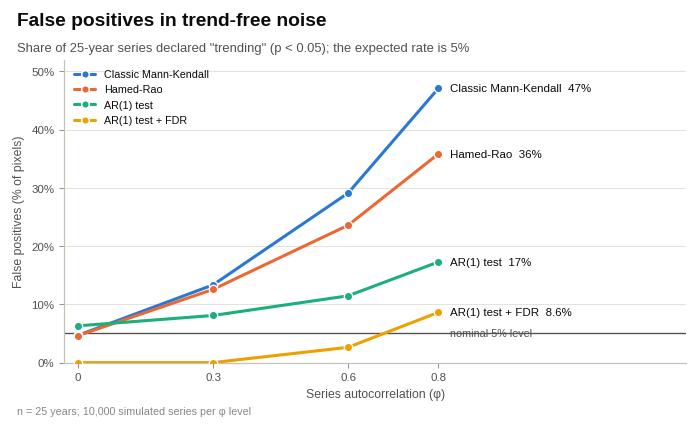

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig3_false_positives.png (+ .pdf)


In [5]:
rng = np.random.default_rng(2)
def ar1(phi, n, m):
    x = np.zeros((n, m)); e = rng.normal(size=(n, m)); x[0] = e[0]
    for t in range(1, n): x[t] = phi*x[t-1] + e[t]*np.sqrt(1-phi**2)
    return x
rows = []
for phi in (0.0, 0.3, 0.6, 0.8):
    X = ar1(phi, 25, 10000); r = mk_sen_hr(X); pa = p_ar1_surrogate(X, r['slope'], r['S'])
    rows.append({'autocorrelation φ': phi, 'Classic MK': np.mean(r['p_naive']<.05), 'Hamed-Rao': np.mean(r['p_hr']<.05),
                 'AR(1) surrogate': np.mean(pa<.05), 'surrogate + FDR': fdr_mask(pa).mean()})
sanity = pd.DataFrame(rows).set_index('autocorrelation φ')
sanity.to_csv(OUT/'sanity_false_positives.csv')
(sanity*100).round(1).astype(str).add('%')
fig_sanidade(sanity)

## 4. Data: fire-season aggregation

In [6]:
VARS = {
 'precip': dict(files=['gpm_025_mensal.nc'], var='precipitation', agg='sum', label=f'Precipitation ({SEASON_NAME}, total)', unit='mm', pct=True, cmap='BrBG'),
 'sm_sup': dict(files=['gldas_sm_pequeno.nc','gldas_025_mensal.nc'], var='SoilMoi0_10cm_inst', agg='mean', label=f'Soil moisture 0–10 cm ({SEASON_NAME})', unit='kg/m²', pct=True, cmap='BrBG'),
 'sm_raiz': dict(files=['gldas_sm_pequeno.nc','gldas_025_mensal.nc'], var='SoilMoi10_40cm_inst', agg='mean', label=f'Soil moisture 10–40 cm ({SEASON_NAME})', unit='kg/m²', pct=True, cmap='BrBG'),
 'vpd': dict(files=['merra2_025_mensal.nc'], var='VPD', agg='mean', label=f'Vapor pressure deficit ({SEASON_NAME})', unit='kPa', pct=False, cmap='RdBu_r'),
 't2m': dict(files=['merra2_025_mensal.nc'], var='T2M_C', agg='mean', label=f'Air temperature at 2 m ({SEASON_NAME})', unit='°C', pct=False, cmap='RdBu_r'),
 'tair': dict(files=['gldas_025_mensal.nc'], var='Tair_f_inst', agg='mean', offset=-273.15, label=f'Air temperature GLDAS - cross-check ({SEASON_NAME})', unit='°C', pct=False, cmap='RdBu_r'),
}
LAT = LON = None
def seasonal(da, agg):
    da = da.transpose('time', 'lat', 'lon')
    sel = da.sel(time=da.time.dt.month.isin(SEASON))
    g = sel.groupby('time.year')
    cnt = sel['time'].groupby('time.year').count()
    out = getattr(g, agg)('time', skipna=False).where(cnt == len(SEASON))
    return out.reindex(year=YEARS)

ANN = {}
for k, v in VARS.items():
    f = next((DATA/x for x in v['files'] if (DATA/x).exists()), None)
    if f is None: print('MISSING:', v['files']); continue
    ds = xr.open_dataset(f)
    ANN[k] = seasonal(ds[v['var']] + v.get('offset', 0), v['agg']).load()
    if LAT is None: LAT, LON = ANN[k].lat.values, ANN[k].lon.values
    print(f"{k:8s} {f.name:24s} valid years: {int(ANN[k].notnull().any(('lat','lon')).sum())}/{len(YEARS)}  mean={float(ANN[k].mean()):.2f} {v['unit']}")

# use only the years that are complete in ALL variables (e.g., final-run GPM lags and may not cover the last year)
ok_years = [y for y in YEARS if all(bool(ANN[k].sel(year=y).notnull().any()) for k in ANN)]
if len(ok_years) < len(YEARS): print('⚠️ years dropped because of incomplete data in some variable:', sorted(set(YEARS) - set(ok_years)))
YEARS = ok_years
ANN = {k: a.sel(year=YEARS) for k, a in ANN.items()}
print(f'analysis period: {YEARS[0]}–{YEARS[-1]} ({len(YEARS)} years)')

precip   gpm_025_mensal.nc        valid years: 24/25  mean=242.17 mm
sm_sup   gldas_025_mensal.nc      valid years: 25/25  mean=23.24 kg/m²
sm_raiz  gldas_025_mensal.nc      valid years: 25/25  mean=70.91 kg/m²
vpd      merra2_025_mensal.nc     valid years: 25/25  mean=1.03 kPa
t2m      merra2_025_mensal.nc     valid years: 25/25  mean=23.31 °C
tair     gldas_025_mensal.nc      valid years: 25/25  mean=23.00 °C
⚠️ years dropped because of incomplete data in some variable: [2025]
analysis period: 2001–2024 (24 years)


## 4b. Third temperature source (CPC, station-based)
MERRA-2 and GLDAS disagree (low spatial r, a step in 2014). **CPC Global Unified Temperature** is station-based (~6–7 thousand stations) and acts as an independent arbiter.

In [7]:
# 4b. Third temperature source: CPC Global Unified Temperature (NOAA PSL), STATION-based, 0.5°.
# Acts as arbiter between MERRA-2 and GLDAS (both reanalyses/models). Tmean = (Tmax+Tmin)/2, fire-season mean.
CPC_FILE = DATA/f"cpc_sazonal_{''.join(map(str, SEASON))}.nc"
BASE = 'https://psl.noaa.gov/thredds/dodsC/Datasets/cpc_global_temp'

CPC_HTTP = 'https://downloads.psl.noaa.gov/Datasets/cpc_global_temp'
import requests, tempfile

def _open_cpc(v, y):
    """1) OPeNDAP (downloads only the subset); 2) on failure, downloads the annual file over HTTP (~380 MB) to temporary disk."""
    try:
        return xr.open_dataset(f'{BASE}/{v}.{y}.nc'), None
    except Exception as e1:
        p = Path(tempfile.gettempdir())/f'{v}.{y}.nc'
        try:
            with requests.get(f'{CPC_HTTP}/{v}.{y}.nc', stream=True, timeout=600) as r:
                r.raise_for_status()
                with open(p, 'wb') as fh:
                    for ch in r.iter_content(1 << 20): fh.write(ch)
            return xr.open_dataset(p), p
        except Exception as e2:
            raise RuntimeError(f'OPeNDAP: {type(e1).__name__} {str(e1)[:90]} | HTTP: {type(e2).__name__} {str(e2)[:90]}')

def _cpc_year(y):
    out = {}
    for v in ('tmax', 'tmin'):
        ds, tmp = _open_cpc(v, y)
        la, lo = ds.lat.values, ds.lon.values
        li = np.where((la >= -35) & (la <= 7))[0]; oi = np.where((lo >= 285) & (lo <= 327))[0]      # lon 0–360
        mo = ds.time.dt.month.values; ti = np.where(np.isin(mo, SEASON))[0]
        sub = ds[v].isel(lat=slice(li.min(), li.max()+1), lon=slice(oi.min(), oi.max()+1), time=slice(ti.min(), ti.max()+1))
        sub = sub.where(sub.time.dt.month.isin(SEASON), drop=True)
        out[v] = sub.mean('time', skipna=True).load()
        if tmp is not None: ds.close(); tmp.unlink(missing_ok=True)
    t = (out['tmax'] + out['tmin']) / 2
    t = t.assign_coords(lon=((t.lon + 180) % 360) - 180).sortby('lon').sortby('lat')
    return t.expand_dims(year=[y])

if CPC_FILE.exists():
    cpc = xr.open_dataarray(CPC_FILE).load()
else:
    try:
        parts = []
        for y in YEARS:
            parts.append(_cpc_year(y)); print('CPC', y, end=' | ')
        cpc = xr.concat(parts, 'year'); cpc.name = 'tmean'; cpc.to_netcdf(CPC_FILE)
    except Exception as e:
        cpc = None; print('\n⚠️ CPC unavailable:', type(e).__name__, str(e)[:300], '\n   Run again (the connection may have dropped) or skip: the analysis continues with 2 sources.')
if cpc is not None:
    ANN['cpc'] = cpc.sel(year=YEARS).interp(lat=LAT, lon=LON, method='linear')      # 0.5° -> 0.25° grid (interpolation: see limitations)
    VARS['cpc'] = dict(label=f'Air temperature CPC - stations ({SEASON_NAME})', unit='°C', pct=False, cmap='RdBu_r')
    print('\ncpc: years', len(YEARS), f"mean={float(ANN['cpc'].mean()):.2f} °C | valid pixels: {int(ANN['cpc'].notnull().all('year').sum())}")


cpc: years 24 mean=24.00 °C | valid pixels: 18107


## 5. Biome mask
Tries the official IBGE polygons via `geobr`; if that fails (no internet or an API change), it falls back to approximate boxes (**for testing only**, with a warning in the output).

In [8]:
BIOMES = ['Amazon', 'Cerrado', 'Pantanal', 'Caatinga', 'Atlantic Forest', 'Pampa']

def _biomes_gdf():
    """IBGE biome polygons. 1) geobr; 2) reads directly the parquet that geobr downloaded (works around a duckdb
    incompatibility); 3) raises an error (falls back to approximate boxes)."""
    try:
        import geobr
        return geobr.read_biomes(year=2019)
    except Exception as e:
        print('geobr.read_biomes failed:', type(e).__name__, '-> trying to read the downloaded parquet directly')
    import glob, geopandas as gpd, os
    pats = [os.path.expanduser('~/.cache/**/biomes_2019*.parquet'), '/root/.cache/**/biomes_2019*.parquet',
            '/tmp/**/biomes_2019*.parquet', '/content/*biomes_2019*.parquet', '/content/*.parquet']
    files = [f for p in pats for f in glob.glob(p, recursive=True)]
    if not files: raise FileNotFoundError('biomes parquet not found; run: !find / -name "biomes_2019*" 2>/dev/null')
    print('reading', files[0])
    try:
        return gpd.read_parquet(files[0])
    except Exception:
        import pandas as pd, shapely.wkb
        df = pd.read_parquet(files[0]); df['geometry'] = df['geometry'].apply(lambda b: shapely.wkb.loads(bytes(b)))
        return gpd.GeoDataFrame(df, geometry='geometry', crs='EPSG:4674')

def get_biomes(lat, lon):
    """Returns (BIO[lat,lon] with the biome index or -1, names, source)."""
    try:
        import regionmask
        gdf = _biomes_gdf()
        col = next(c for c in gdf.columns if 'name' in c.lower() or 'bioma' in c.lower())
        key = {'amaz':'Amazon','cerrado':'Cerrado','pantanal':'Pantanal','caatinga':'Caatinga','atl':'Atlantic Forest','pampa':'Pampa'}
        def norm(s):
            s = str(s).lower()
            return next((v for k, v in key.items() if k in s), None)
        gdf = gdf.assign(b=gdf[col].map(norm)).dropna(subset=['b']).reset_index(drop=True)
        try: reg = regionmask.from_geopandas(gdf, names='b', overlap=False)   # tolerates overlap at the borders
        except TypeError: reg = regionmask.from_geopandas(gdf, names='b')
        m = reg.mask(lon, lat).values
        names = list(reg.names)
        idx = np.where(np.isnan(m), -1, m).astype(int)
        out = np.full(idx.shape, -1)
        for i, n in enumerate(names): out[idx == i] = BIOMES.index(n)
        return out, BIOMES, 'IBGE (official polygons)'
    except Exception as e:
        print('⚠️ official biomes unavailable ->', type(e).__name__, str(e)[:160])
        print('⚠️ using APPROXIMATE BOXES (testing only; per-biome numbers are NOT reliable)')
        LO, LA = np.meshgrid(lon, lat)
        out = np.full(LO.shape, -1)
        out[(LO > -68) & (LO < -44) & (LA > -10) & (LA < 4)] = 0       # Amazon (approx.)
        out[(LO > -53) & (LO < -43) & (LA > -20) & (LA < -8)] = 1      # Cerrado (approx.)
        out[(LO > -59) & (LO < -55) & (LA > -22) & (LA < -15.5)] = 2   # Pantanal (approx.)
        return out, BIOMES, 'APPROXIMATE BOXES (test)'

BIO, BIO_NAMES, BIO_SRC = get_biomes(LAT, LON)
print('biome mask:', BIO_SRC, '| pixels per biome:', {n: int((BIO == i).sum()) for i, n in enumerate(BIO_NAMES) if (BIO == i).any()})

biomes_2019_simplified.parquet: 100%|██████████| 3.14M/3.14M [00:00<00:00, 19.9MB/s]


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

geobr.read_biomes failed: AttributeError -> trying to read the downloaded parquet directly
reading /tmp/geobr_cd0_sqod/biomes_2019_simplified.parquet
biome mask: IBGE (official polygons) | pixels per biome: {'Amazon': 5516, 'Cerrado': 2678, 'Pantanal': 204, 'Caatinga': 1131, 'Atlantic Forest': 1554, 'Pampa': 291}


## 6. Per-pixel trend (Sen + Mann-Kendall + FDR)

In [9]:
def trend_map(A, pct):
    """A: DataArray (year, lat, lon). Returns a Dataset with slope/decade, p-values and the FDR mask."""
    n = A.sizes['year']
    X = A.transpose('year', 'lat', 'lon').values.reshape(n, -1)
    valid = np.isfinite(X).all(0)
    r = mk_sen_hr(X[:, valid])
    p_ar1 = p_ar1_surrogate(X[:, valid], r['slope'], r['S'])
    mean = X[:, valid].mean(0)
    slope_dec = r['slope'] * 10 * (100 / np.where(mean != 0, mean, np.nan) if pct else 1)
    def back(v):
        o = np.full(X.shape[1], np.nan); o[valid] = v; return o.reshape(A.sizes['lat'], A.sizes['lon'])
    p_full = back(p_ar1)
    sig = fdr_mask(p_full.ravel(), ALPHA).reshape(p_full.shape)
    return xr.Dataset({'slope_dec': (('lat','lon'), back(slope_dec)), 'p_ar1': (('lat','lon'), p_full),
                       'p_hr': (('lat','lon'), back(r['p_hr'])), 'p_naive': (('lat','lon'), back(r['p_naive'])),
                       'sig_fdr': (('lat','lon'), sig)}, coords={'lat': A.lat, 'lon': A.lon})

TM = {k: trend_map(ANN[k], VARS[k]['pct']) for k in ANN}
resumo = []
for k, t in TM.items():
    v = t['p_ar1'].notnull().sum().item()
    resumo.append({'variable': VARS[k]['label'], 'pixels': v,
                   '% sig. (p<0.05, uncorrected)': 100*float((t['p_naive'] < .05).sum()/v),
                   '% sig. (AR1, no FDR)': 100*float((t['p_ar1'] < .05).sum()/v),
                   '% sig. (AR1 + FDR)': 100*float(t['sig_fdr'].sum()/v)})
resumo = pd.DataFrame(resumo).set_index('variable').round(1)
xr.Dataset({f'{k}_{n}': t[n] for k, t in TM.items() for n in t.data_vars}).to_netcdf(OUT/'tendencias_pixel.nc')
resumo

,pixels,"% sig. (p<0.05, uncorrected)","% sig. (AR1, no FDR)",% sig. (AR1 + FDR)
variable,,,,
"Precipitation (Aug–Oct, total)",25600,15.3,17.5,6.2
Soil moisture 0–10 cm (Aug–Oct),18170,35.0,33.5,23.8
Soil moisture 10–40 cm (Aug–Oct),18170,36.4,31.0,19.6
Vapor pressure deficit (Aug–Oct),25600,36.7,35.4,29.8
Air temperature at 2 m (Aug–Oct),25600,51.2,47.0,45.2
Air temperature GLDAS - cross-check (Aug–Oct),18294,58.0,45.6,44.3
Air temperature CPC - stations (Aug–Oct),18107,46.6,42.9,40.5


## 7. Maps: what changes, where, by how much, and whether it is significant
Color = slope per decade (precipitation and soil moisture in **% of the mean per decade**; VPD and temperature in units/decade). **Stippling = significant after FDR.** Lines = biomes.

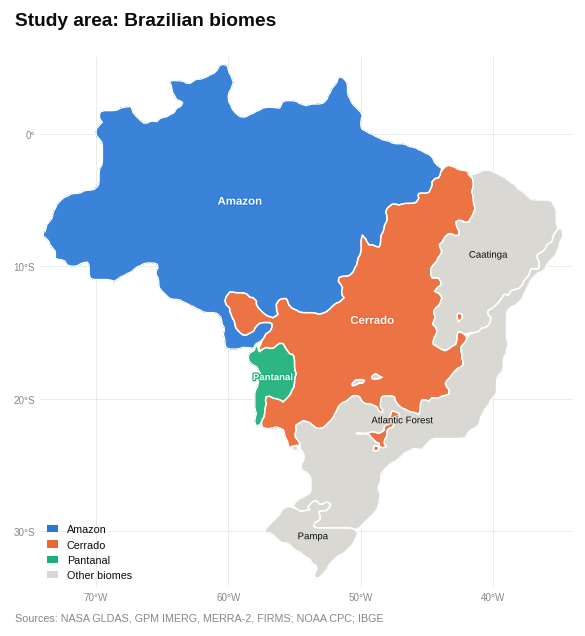

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig1_study_area.png (+ .pdf)


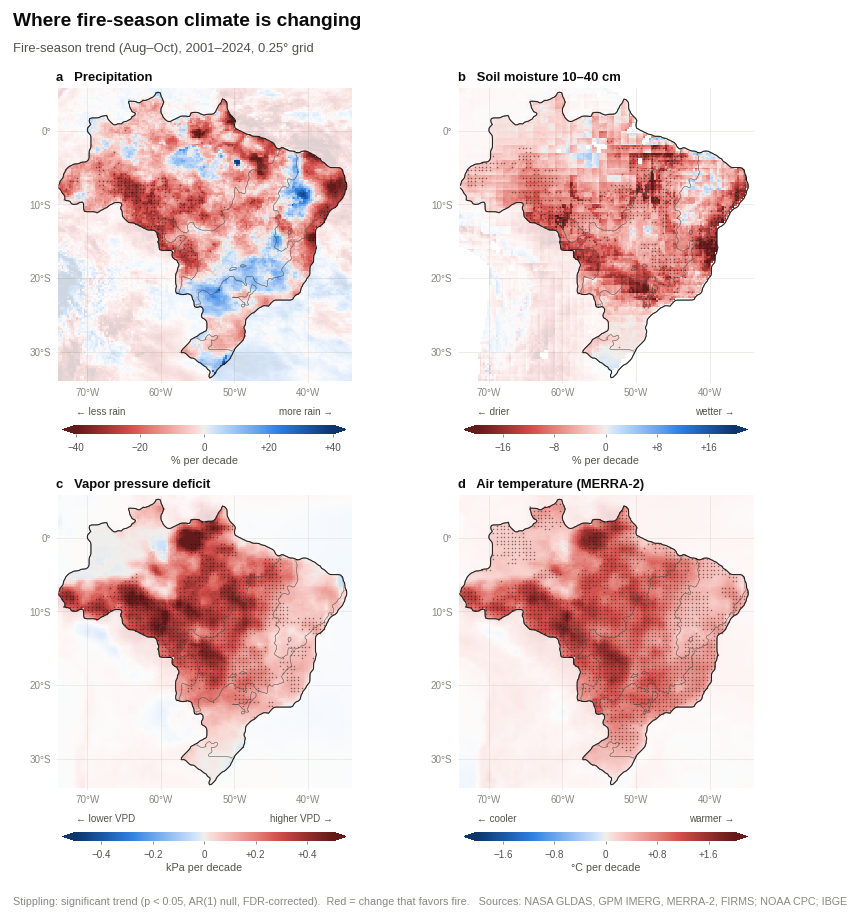

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig2_trend_maps.png (+ .pdf)


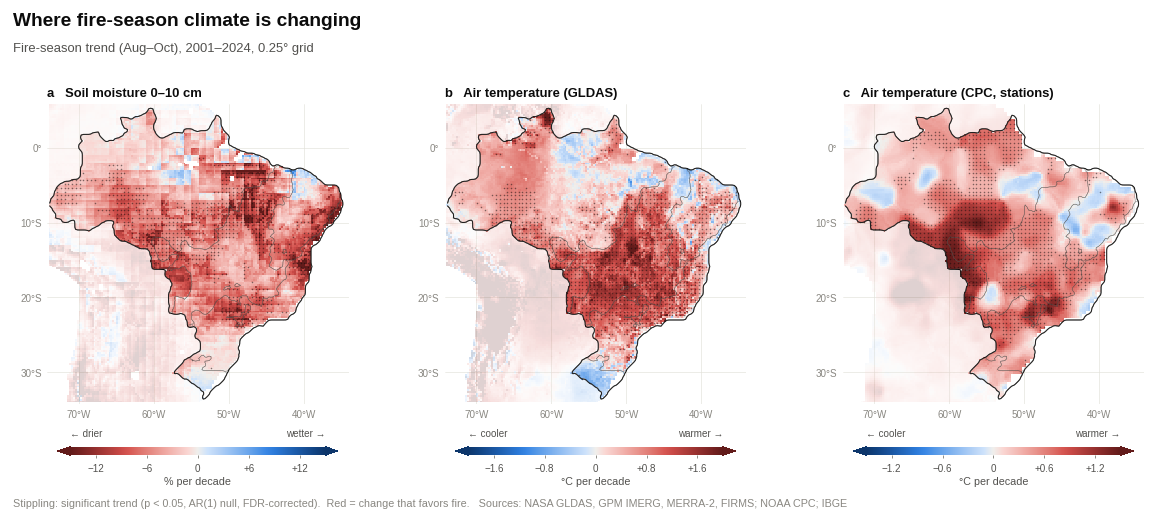

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/figS1_supplementary_maps.png (+ .pdf)


In [10]:
fig_area_estudo()
fig_mapas()                                                    # precip, soil moisture 10–40 cm, VPD, T2M
if 'sm_sup' in TM: fig_mapas(tuple(k for k in ('sm_sup', 'tair', 'cpc') if k in TM), ncols=3, name='figS1_supplementary_maps')

## 8. By biome: mean series, trend and change point

In [11]:
W = np.cos(np.deg2rad(LAT))[:, None] * np.ones((1, len(LON)))   # area weight (cos lat)

def biome_series(A, b):
    """Area-weighted (cos lat) mean inside the biome, year by year. NaN if the year has no data (NEVER becomes zero)."""
    m = (BIO == b)
    if not m.any(): return None
    a = A.transpose('year', 'lat', 'lon').values
    w = np.where(m[None] & np.isfinite(a), W[None], 0.0)          # weight only where there is data, in each year
    num = (np.where(np.isfinite(a), a, 0.0) * w).sum((1, 2))
    den = w.sum((1, 2))
    return np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)

rows, SER = [], {}
for k in ANN:
    for b, name in enumerate(BIO_NAMES):
        s = biome_series(ANN[k], b)
        if s is None or not np.isfinite(s).all(): continue
        SER[(k, name)] = s
        h = mk.hamed_rao_modification_test(s); o = mk.original_test(s)
        r1 = mk_sen_hr(s[:, None]); pa = p_ar1_surrogate(s[:, None], r1['slope'], r1['S'], nsim=20000)[0]
        ic, pp = pettitt(s)
        dec = h.slope * 10 * (100 / s.mean() if VARS[k]['pct'] else 1)
        rows.append({'variable': VARS[k]['label'], 'biome': name, 'trend/decade': round(dec, 2),
                     'unit': '%' if VARS[k]['pct'] else VARS[k]['unit'], 'p (AR1)': round(pa, 3),
                     'p (Hamed-Rao)': round(h.p, 3), 'p (classic)': round(o.p, 3),
                     'Pettitt shift (year)': YEARS[ic] + 1 if pp < .1 else '—', 'Pettitt p': round(pp, 3)})
tab = pd.DataFrame(rows); tab.to_csv(OUT/'trend_by_biome.csv', index=False)
tab

,variable,biome,trend/decade,unit,p (AR1),p (Hamed-Rao),p (classic),Pettitt shift (year),Pettitt p
0,"Precipitation (Aug–Oct, total)",Amazon,-8.47,%,0.095,0.107,0.107,—,0.326
1,"Precipitation (Aug–Oct, total)",Cerrado,-3.69,%,0.512,0.387,0.637,—,1.000
2,"Precipitation (Aug–Oct, total)",Pantanal,-19.21,%,0.030,0.087,0.087,—,0.363
3,"Precipitation (Aug–Oct, total)",Caatinga,-13.98,%,0.460,0.277,0.413,—,1.000
4,"Precipitation (Aug–Oct, total)",Atlantic Forest,-1.44,%,0.662,0.710,0.710,—,1.000
5,"Precipitation (Aug–Oct, total)",Pampa,3.60,%,0.662,0.710,0.710,—,1.000
6,Soil moisture 0–10 cm (Aug–Oct),Amazon,-3.78,%,0.037,0.031,0.031,—,0.344
7,Soil moisture 0–10 cm (Aug–Oct),Cerrado,-6.71,%,0.003,NaN,0.031,—,0.260
8,Soil moisture 0–10 cm (Aug–Oct),Pantanal,-8.01,%,0.200,0.107,0.107,2019,0.079
9,Soil moisture 0–10 cm (Aug–Oct),Caatinga,-5.98,%,0.088,0.063,0.063,2012,0.063


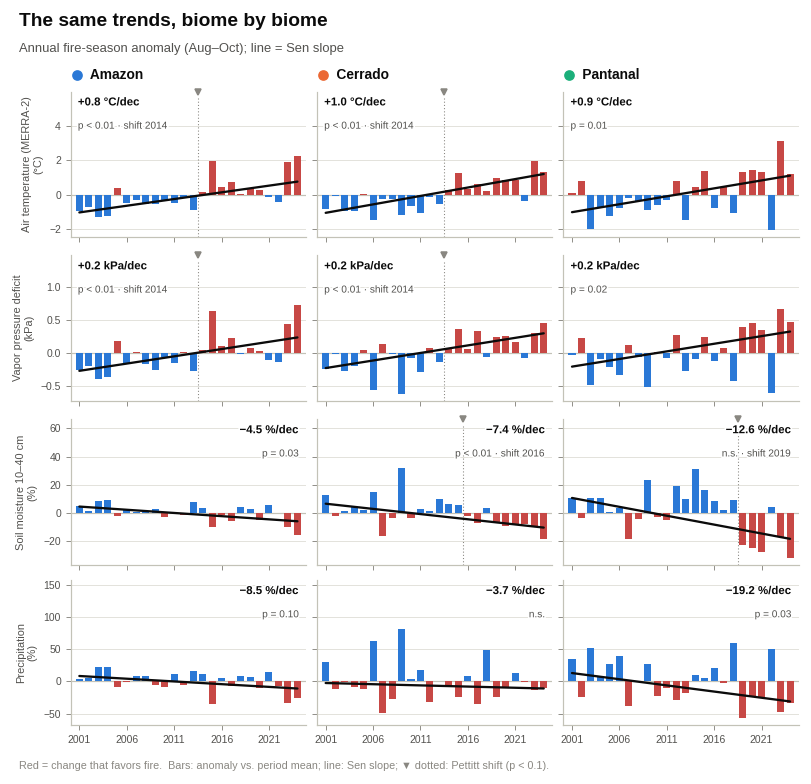

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig4_biome_series.png (+ .pdf)


In [12]:
fig_series_biomas()   # bars = anomaly, line = Sen, ▼ = Pettitt shift

## 9. (Optional) Fire: same analysis + consistency with the drivers
Runs if the fire counts are in `data/` with enough years. Shows the fire trend by biome and the Spearman correlation with each driver. **Correlation is not causation**: ENSO, deforestation and fire management are confounders.

### 9a. Fire ingestion (NASA FIRMS, MODIS/Aqua)
Downloads the annual country files, keeps only the **Aqua** satellite (reference, avoids mixing sensors) and counts active fires per month and biome. **Caution:** Aqua stops holding its fixed orbit from ~2022 (drift in overpass time), which may reduce detections. Read the fire trend with that caveat.

In [13]:
# 9a. Active fires: NASA FIRMS (MODIS Collection 6.1, annual country file), reference satellite AQUA.
# Aqua has operated since Jul 2002 -> the series starts in 2002 (complete Aug–Oct season). Writes data/focos_firms_aqua_mensal.csv
# (file name kept so an existing cache on Drive is reused; new files have columns time, biome, fires, frp_sum;
# the old Portuguese column names are also accepted when reading).
import requests, geopandas as gpd
FIRMS_DIR = DATA/'firms'; FIRMS_DIR.mkdir(exist_ok=True)
fp = DATA/'focos_firms_aqua_mensal.csv'      # NEW file (does not reuse the old INPE CSV, which only had 2026)
FIRE_YEARS = [y for y in YEARS if y >= 2002]

def _firms_file(y):
    for f in list(FIRMS_DIR.glob(f'*{y}*Brazil*.csv')) + list(FIRMS_DIR.glob(f'*{y}*Brasil*.csv')): return f
    url = f'https://firms.modaps.eosdis.nasa.gov/data/country/modis/{y}/modis_{y}_Brazil.csv'
    try:
        r = requests.get(url, timeout=180)
        if r.ok and r.content[:8].lower().startswith(b'latitude'):
            f = FIRMS_DIR/f'modis_{y}_Brazil.csv'; f.write_bytes(r.content); return f
    except Exception: pass
    return None

def _labeled_biomes():
    gdf = _biomes_gdf(); col = next(c for c in gdf.columns if 'name' in c.lower() or 'bioma' in c.lower())
    key = {'amaz':'Amazon','cerrado':'Cerrado','pantanal':'Pantanal','caatinga':'Caatinga','atl':'Atlantic Forest','pampa':'Pampa'}
    gdf = gdf.assign(biome=gdf[col].map(lambda s: next((v for k, v in key.items() if k in str(s).lower()), None))).dropna(subset=['biome'])
    return gdf[['biome', 'geometry']].to_crs('EPSG:4326')

if not fp.exists():
    missing = [y for y in FIRE_YEARS if _firms_file(y) is None]
    if missing:
        print('⚠️ Could not download the years:', missing)
        print('   Download manually from https://firms.modaps.eosdis.nasa.gov/country/ (MODIS, Brazil, each year; requires an Earthdata login)')
        print('   and upload the .csv files to', FIRMS_DIR, '— then run this cell again.')
    else:
        gb = _labeled_biomes(); out = []
        for y in FIRE_YEARS:
            d = pd.read_csv(_firms_file(y), usecols=lambda c: c in ('latitude', 'longitude', 'acq_date', 'satellite', 'frp', 'type'))
            d = d[d.satellite.astype(str).str.lower().str.startswith('aqua')]
            if 'type' in d: d = d[d['type'].fillna(0) == 0]                       # vegetation fires only (excludes static/offshore sources)
            pts = gpd.GeoDataFrame(d, geometry=gpd.points_from_xy(d.longitude, d.latitude), crs='EPSG:4326')
            j = gpd.sjoin(pts, gb, how='inner', predicate='within'); j = j[~j.index.duplicated()]
            j['time'] = pd.to_datetime(j.acq_date).dt.to_period('M').dt.to_timestamp()
            out.append(j.groupby(['time', 'biome']).agg(fires=('frp', 'size'), frp_sum=('frp', 'sum')).reset_index()); print(y, len(d), end=' | ')
        pd.concat(out).to_csv(fp, index=False); print('\nsaved', fp)
else:
    print('using', fp, '(delete it to redo)')

using /content/drive/MyDrive/fogo_trends/data/focos_firms_aqua_mensal.csv (delete it to redo)


enough fire history (>=15 years): True | years: (np.int64(2002), np.int64(2024))


,biome,type,trend/decade (% of mean),p (Hamed-Rao),Pettitt shift
0,Amazon,ACTIVE FIRES,-28.50,0.185,2009
1,Amazon,Spearman ρ with Precipitation,-0.22,0.319,detrended: ρ=-0.40 (p=0.062)
2,Amazon,Spearman ρ with Soil moisture 0–10 cm,-0.13,0.553,detrended: ρ=-0.41 (p=0.049)
3,Amazon,Spearman ρ with Soil moisture 10–40 cm,-0.19,0.383,detrended: ρ=-0.45 (p=0.032)
4,Amazon,Spearman ρ with Vapor pressure deficit,0.00,0.989,detrended: ρ=0.35 (p=0.104)
5,Amazon,Spearman ρ with Air temperature at 2 m,-0.08,0.703,detrended: ρ=0.31 (p=0.154)
6,Amazon,Spearman ρ with Air temperature GLDAS - cross-...,-0.17,0.435,detrended: ρ=0.16 (p=0.461)
7,Amazon,Spearman ρ with Air temperature CPC - stations,-0.32,0.135,detrended: ρ=0.14 (p=0.533)
8,Cerrado,ACTIVE FIRES,-18.10,0.000,—
9,Cerrado,Spearman ρ with Precipitation,-0.55,0.007,detrended: ρ=-0.63 (p=0.001)


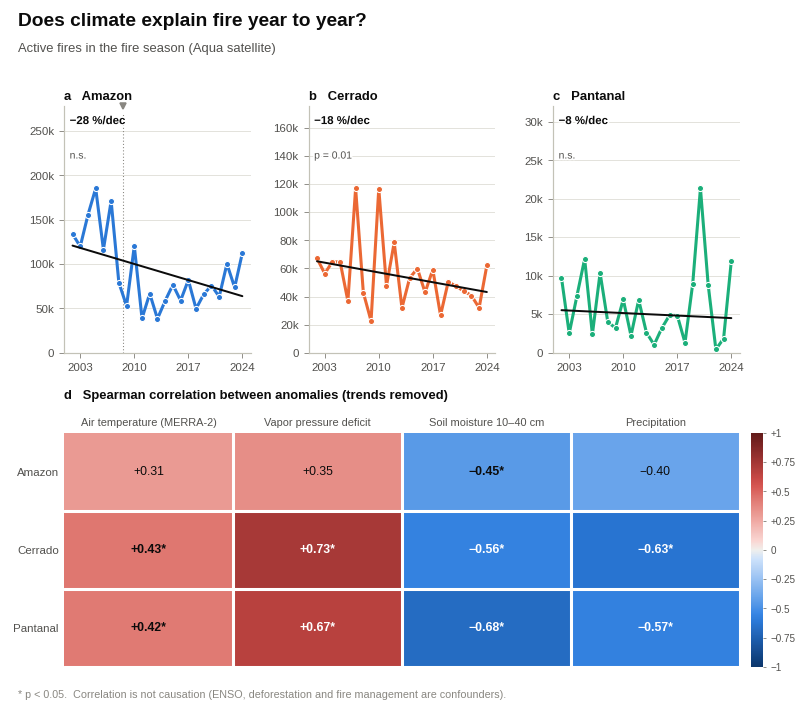

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig5_fire_and_climate.png (+ .pdf)


In [14]:
has_fire = False
if fp.exists():
    fb = pd.read_csv(fp, parse_dates=['time']).rename(columns={'bioma': 'biome', 'focos': 'fires', 'frp_soma': 'frp_sum'})
    fb['biome'] = fb['biome'].replace({'Amazônia': 'Amazon', 'Mata Atlântica': 'Atlantic Forest'})     # cache from the Portuguese version
    fb = fb[fb.time.dt.month.isin(SEASON)].groupby([fb.time.dt.year, 'biome']).fires.sum().unstack()
    fb = fb.reindex(YEARS).dropna(how='all')                      # only years with data (Aqua: 2002+)
    has_fire = len(fb) >= 15
print('enough fire history (>=15 years):', has_fire, '| years:', (fb.index.min(), fb.index.max()) if has_fire else '')
if has_fire:
    from scipy.stats import spearmanr
    ix = [YEARS.index(y) for y in fb.index]; rows = []
    for b in [c for c in ['Amazon', 'Cerrado', 'Pantanal'] if c in fb and fb[c].notna().all()]:
        s = fb[b].values.astype(float); h = mk.hamed_rao_modification_test(s); ic, pp = pettitt(s)
        rows.append({'biome': b, 'type': 'ACTIVE FIRES', 'trend/decade (% of mean)': round(h.slope*10/s.mean()*100, 1),
                     'p (Hamed-Rao)': round(h.p, 3), 'Pettitt shift': int(fb.index[ic])+1 if pp < .1 else '—'})
        for k in ANN:
            if (k, b) in SER:
                x = np.asarray(SER[(k, b)])[ix]; rho, p = spearmanr(s, x)
                rd, pd_ = spearmanr(_detr(s), _detr(x))          # detrended: measures only year-to-year covariation
                rows.append({'biome': b, 'type': f"Spearman ρ with {VARS[k]['label'].split(' (')[0]}", 'trend/decade (% of mean)': round(rho, 2), 'p (Hamed-Rao)': round(p, 3), 'Pettitt shift': f'detrended: ρ={rd:.2f} (p={pd_:.3f})'})
    tab_fogo = pd.DataFrame(rows); tab_fogo.to_csv(OUT/'fire_trend_and_correlation.csv', index=False); display(tab_fogo)
    fig_fogo(fb)

## 10. Robustness: do the numbers hold with another source and another window?
Before reporting a trend, two checks: **(a)** does MERRA-2 agree with a second product (GLDAS temperature) and with station data (CPC)? **(b)** does the result change if we end in 2022 (without the 2023–24 extremes) or drop the first years? Series of 24 points are sensitive to their ends.

Mean trend over Brazil (°C/dec): {'t2m': 0.79, 'tair': 0.59, 'cpc': 0.45}
  spatial r t2m x tair: 0.16
  spatial r t2m x cpc: 0.49
  spatial r tair x cpc: 0.26


trend/decade  \
variable        Air temperature CPC - stations (Aug–Oct)   
biome                                                      
Amazon                                              0.38   
Atlantic Forest                                     0.45   
Caatinga                                            0.08   
Cerrado                                             0.53   
Pampa                                               0.27   
Pantanal                                            1.12   

                                                               \
variable        Air temperature GLDAS - cross-check (Aug–Oct)   
biome                                                           
Amazon                                                   0.41   
Atlantic Forest                                          0.74   
Caatinga                                                 0.39   
Cerrado                                                  0.97   
Pampa                                                   -0.32   
Pantanal                                                 1.11   

                                                  \
variable        Air temperature at 2 m (Aug–Oct)   
biome                                              
Amazon                                      0.78   
Atlantic Forest                             0.71   
Caatinga                                    0.42   
Cerrado                                     0.98   
Pampa                                       0.31   
Pantanal                                    0.92   

                                                 p (AR1)  \
variable        Air temperature CPC - stations (Aug–Oct)   
biome                                                      
Amazon                                               0.0   
Atlantic Forest                                      0.1   
Caatinga                                           0.196   
Cerrado                                              0.0   
Pampa                                              0.342   
Pantanal                                           0.008   

                                                               \
variable        Air temperature GLDAS - cross-check (Aug–Oct)   
biome                                                           
Amazon                                                   0.06   
Atlantic Forest                                         0.008   
Caatinga                                                0.003   
Cerrado                                                   0.0   
Pampa                                                   0.479   
Pantanal                                                0.001   

                                                  \
variable        Air temperature at 2 m (Aug–Oct)   
biome                                              
Amazon                                     0.001   
Atlantic Forest                            0.001   
Caatinga                                   0.013   
Cerrado                                      0.0   
Pampa                                      0.351   
Pantanal                                   0.011   

                                    Pettitt shift (year)  \
variable        Air temperature CPC - stations (Aug–Oct)   
biome                                                      
Amazon                                              2009   
Atlantic Forest                                        —   
Caatinga                                               —   
Cerrado                                             2014   
Pampa                                                  —   
Pantanal                                               —   

                                                               \
variable        Air temperature GLDAS - cross-check (Aug–Oct)   
biome                                                           
Amazon                                                      —   
Atlantic Forest                                    

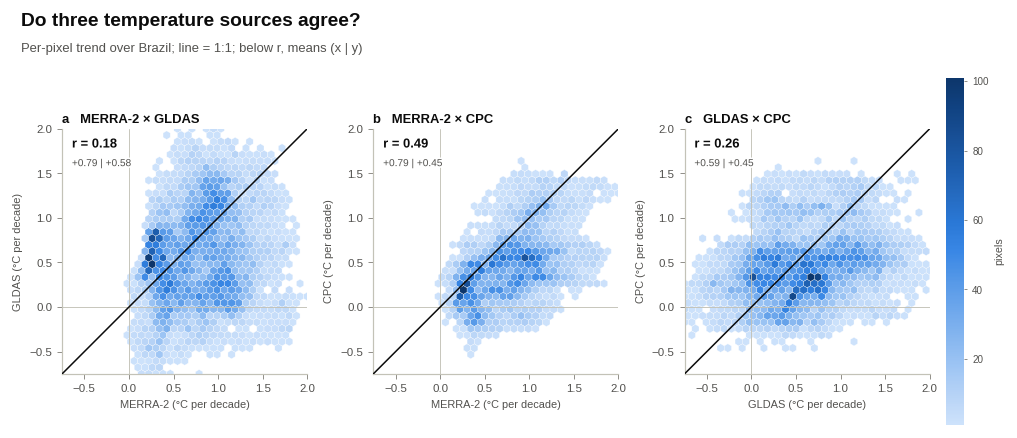

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig6a_temperature_agreement.png (+ .pdf)


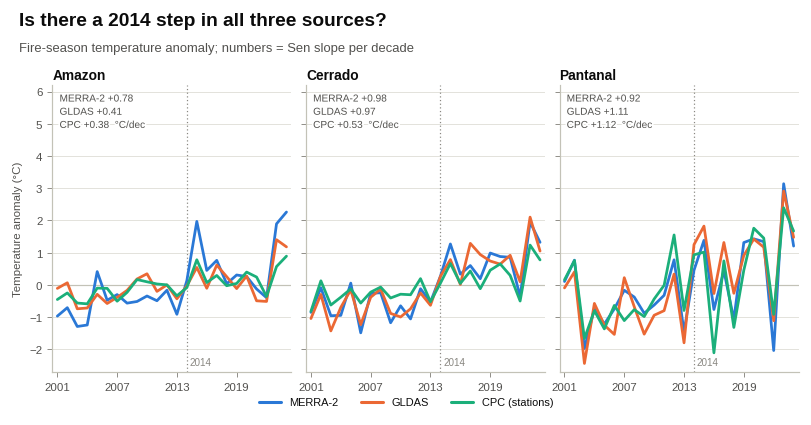

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig6c_temperature_three_sources.png (+ .pdf)


In [15]:
# (a) Do the temperature sources agree? (MERRA-2 x GLDAS x CPC)
if 't2m' in TM and 'tair' in TM:
    ks = [k for k in ('t2m', 'tair', 'cpc') if k in TM]
    land = (BIO >= 0)
    for k in ks: land = land & np.isfinite(TM[k]['slope_dec'].values)
    print('Mean trend over Brazil (°C/dec):', {k: round(float(TM[k]['slope_dec'].values[land].mean()), 2) for k in ks})
    for i in range(len(ks)):
        for j in range(i+1, len(ks)):
            r = np.corrcoef(TM[ks[i]]['slope_dec'].values[land], TM[ks[j]]['slope_dec'].values[land])[0, 1]
            print(f'  spatial r {ks[i]} x {ks[j]}: {r:.2f}')
    cmp = tab[tab['variable'].str.startswith('Air temperature')].pivot(index='biome', columns='variable', values=['trend/decade', 'p (AR1)', 'Pettitt shift (year)'])
    cmp.to_csv(OUT/'robustness_temperature_sources.csv'); display(cmp)
    fig_concordancia_temperatura(); fig_temperatura_tres_fontes()
else:
    print('Full GLDAS (gldas_025_mensal.nc with Tair_f_inst) not found: skipping (a).')

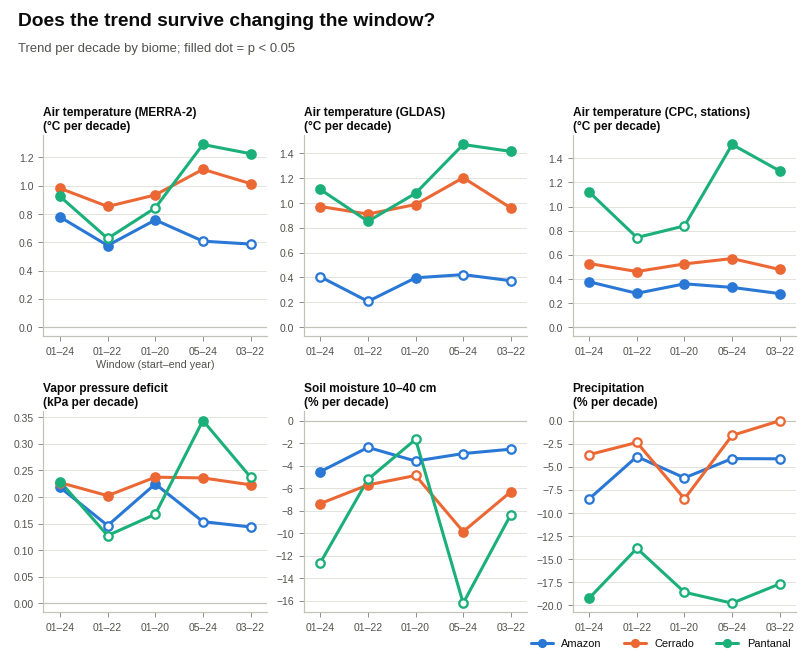

saved: /content/drive/MyDrive/fogo_trends/resultados/figures/fig6b_window_sensitivity.png (+ .pdf)


,variable,biome,2001–2024,2001–2022,2001–2020,2005–2024,2003–2022
0,Air temperature at 2 m,Amazon,+0.78*,+0.58*,+0.76*,+0.61,+0.59
1,Air temperature at 2 m,Cerrado,+0.98*,+0.85*,+0.93*,+1.11*,+1.01*
2,Air temperature at 2 m,Pantanal,+0.92*,+0.63,+0.84,+1.29*,+1.23*
3,Air temperature GLDAS - cross-check,Amazon,+0.41,+0.21,+0.40*,+0.42,+0.37
4,Air temperature GLDAS - cross-check,Cerrado,+0.97*,+0.91*,+0.99*,+1.20*,+0.96*
5,Air temperature GLDAS - cross-check,Pantanal,+1.11*,+0.85*,+1.08*,+1.47*,+1.41*
6,Air temperature CPC - stations,Amazon,+0.38*,+0.28*,+0.36*,+0.33*,+0.28*
7,Air temperature CPC - stations,Cerrado,+0.53*,+0.46*,+0.52*,+0.57*,+0.48*
8,Air temperature CPC - stations,Pantanal,+1.12*,+0.74,+0.84,+1.51*,+1.29*
9,Vapor pressure deficit,Amazon,+0.22*,+0.15,+0.22*,+0.15,+0.14


In [16]:
# (b) sensitivity to the time window: trend per decade, by biome ('*' = p(AR1) < 0.05)
WINDOWS = [(2001, 2024), (2001, 2022), (2001, 2020), (2005, 2024), (2003, 2022)]
focus = [k for k in ['t2m', 'tair', 'cpc', 'vpd', 'sm_raiz', 'precip'] if k in ANN]
rows, long = [], []
for k in focus:
    for name in ['Amazon', 'Cerrado', 'Pantanal']:
        s = SER.get((k, name))
        if s is None: continue
        row = {'variable': VARS[k]['label'].split(' (')[0], 'biome': name}
        for lo, hi in WINDOWS:
            idx = [i for i, y in enumerate(YEARS) if lo <= y <= hi]
            x = s[idx]; r1 = mk_sen_hr(x[:, None]); pa = p_ar1_surrogate(x[:, None], r1['slope'], r1['S'], nsim=10000)[0]
            d = r1['slope'][0] * 10 * (100 / x.mean() if VARS[k]['pct'] else 1)
            long.append(dict(k=k, biome=name, window=f'{lo}–{hi}', slope_dec=d, p=pa))
            row[f'{lo}–{hi}'] = f"{d:+.2f}{'*' if pa < .05 else ''}"
        rows.append(row)
sens = pd.DataFrame(rows); sens.to_csv(OUT/'robustness_time_window.csv', index=False)
fig_robustez_b(pd.DataFrame(long))
sens

In [17]:
# (c) does the change point (Pettitt) show up in all temperature products?
pt = tab[tab['variable'].str.startswith('Air temperature') & tab['biome'].isin(['Amazon', 'Cerrado', 'Pantanal'])][['variable', 'biome', 'Pettitt shift (year)', 'Pettitt p']]
pt

,variable,biome,Pettitt shift (year),Pettitt p
24,Air temperature at 2 m (Aug–Oct),Amazon,2014,0.003
25,Air temperature at 2 m (Aug–Oct),Cerrado,2014,0.001
26,Air temperature at 2 m (Aug–Oct),Pantanal,—,0.245
30,Air temperature GLDAS - cross-check (Aug–Oct),Amazon,—,0.121
31,Air temperature GLDAS - cross-check (Aug–Oct),Cerrado,2014,0.000
32,Air temperature GLDAS - cross-check (Aug–Oct),Pantanal,2014,0.012
36,Air temperature CPC - stations (Aug–Oct),Amazon,2009,0.011
37,Air temperature CPC - stations (Aug–Oct),Cerrado,2014,0.012
38,Air temperature CPC - stations (Aug–Oct),Pantanal,—,0.204


## Notes and limitations (for the report)
- **Primary test:** Mann-Kendall against an AR(1) null with φ corrected for small-sample bias (Kendall, 1954). On trend-free noise it greatly reduces false positives relative to the classic test and to Hamed-Rao (see section 3), at the cost of some power.
- **FDR:** Benjamini-Hochberg with α_FDR = 2α (Wilks, 2016). Neighboring pixels are correlated; BH is reasonable under positive dependence, but it is an approximation.
- **Grid:** linear interpolation to 0.25° (GPM, MERRA-2, CPC): an approximation. MERRA-2: VPD computed from monthly mean T and humidity (approximate).
- **25-year trends** are sensitive to extremes (e.g., the 2010 drought, 2024). Test other seasons (`SEASON`) and windows.
- **Fire:** Aqua active fires are affected by the satellite's orbital drift; correlation with drivers does not imply causation.